# Nobilia: quantifying the improvement scenarios

Companion notebook to the executive report *Operational Excellence at Nobilia* (University of Cologne, M.Sc. Supply Chain Management, 2026).

During a **virtual-reality factory tour** of Nobilia (a German kitchen manufacturer), our team timed several production activities. This notebook:

1. analyses the **sample measurements** taken during the tour;
2. rebuilds the four **improvement scenarios** of the report as small, transparent models;
3. runs **sensitivity analyses**, to show when each improvement pays off and when it doesn't.

⚠️ All improvements are *illustrative scenarios* based on short observations and stated assumptions, not observed gains.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path(".")
FIG = Path(".")

ACCENT = "#2a78d6"     # blue
SECOND = "#eb6834"     # orange
NEUTRAL = "#c3c2b7"    # grey
INK = "#52514e"
GRID = "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": NEUTRAL, "axes.labelcolor": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

SHIFT_S = 8 * 60 * 60   # one 8-hour shift in seconds
SHIFT_MIN = 8 * 60      # ... and in minutes

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

## 1. Sample measurements from the tour

We counted the parts leaving the **edge-finishing** line in five one-minute windows. In the first window we saw a machine disruption.

Mean of all 5 windows:            35.6 parts/min
Mean without the disrupted window: 39.0 parts/min
Output in the disrupted window vs normal: -44%


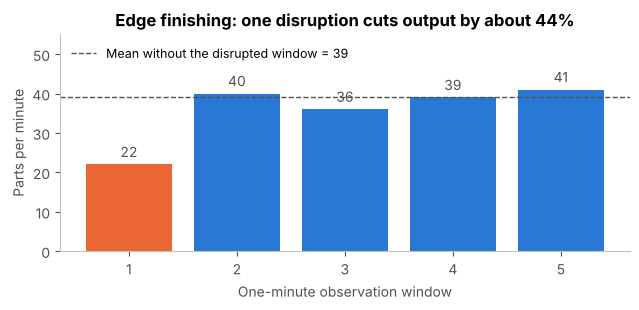

In [2]:
edge = pd.read_csv(DATA / "edge_finishing_observations.csv")
mean_all = edge["parts"].mean()
mean_clean = edge.loc[edge["note"].isna(), "parts"].mean()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
colors = [SECOND if isinstance(n, str) else ACCENT for n in edge["note"]]
bars = ax.bar(edge["window"].astype(str), edge["parts"], color=colors)
ax.bar_label(bars, padding=3, color=INK)
ax.axhline(mean_clean, color=INK, linestyle="--", linewidth=1, label=f"Mean without the disrupted window = {mean_clean:.0f}")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_xlabel("One-minute observation window")
ax.set_ylabel("Parts per minute")
ax.set_ylim(0, 55)
ax.set_title("Edge finishing: one disruption cuts output by about 44%")
save(fig, "edge_finishing_observations.png")
plt.show()

print(f"Mean of all 5 windows:            {mean_all:.1f} parts/min")
print(f"Mean without the disrupted window: {mean_clean:.1f} parts/min")
print(f"Output in the disrupted window vs normal: {(22 / mean_clean - 1) * 100:.0f}%")

**Reading the chart:** a single stop drags the average down from 39 to 35.6 parts/min. Disruptions, not the machine's speed, are the first thing to look at. This is the starting point of scenario 2.

The other measurements:

In [3]:
print(pd.read_csv(DATA / "sample_measurements.csv")[["process", "sample", "mean", "unit"]].to_string(index=False))

                              process            sample  mean                unit
                       Edge finishing 5 x 1-min windows  35.6           parts/min
              Robotic drawer assembly 5 x 1-min windows   4.4 drawers/min/station
                       Final assembly 5 x 1-min windows   2.8        cabinets/min
Manual packaging (carton application)      5 operations  17.4         s/operation
    Front picking (one 13-item order)           1 order 150.0             s/order


## 2. Scenario 1: Pick-by-Light for manual front picking

Fronts come in at least 17,600 colour/size combinations, so they are picked by hand. One observed order of **13 fronts took 150 s**. Shelf lights showing the next item could save search time.

$$\text{orders per shift} = \frac{\text{shift length (s)}}{\text{time per order (s)}}$$

 seconds saved per item  time per order (s)  orders per shift  extra orders
                      0                 150               192             0
                      1                 137               210            18
                      2                 124               232            40


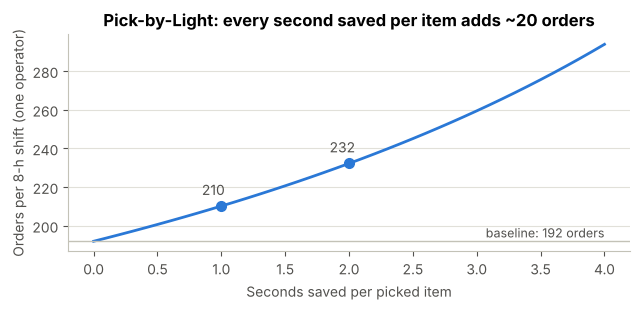

In [4]:
ITEMS, BASE = 13, 150

def orders_per_shift(seconds_saved_per_item):
    return SHIFT_S / (BASE - ITEMS * seconds_saved_per_item)

rows = []
for saved in [0, 1, 2]:
    t = BASE - ITEMS * saved
    rows.append({"seconds saved per item": saved, "time per order (s)": t,
                 "orders per shift": round(orders_per_shift(saved)),
                 "extra orders": round(orders_per_shift(saved) - orders_per_shift(0))})
print(pd.DataFrame(rows).to_string(index=False))

# Sensitivity: how does the gain grow as savings per item increase?
s = [x / 10 for x in range(0, 41)]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(s, [orders_per_shift(x) for x in s], color=ACCENT, linewidth=2)
for x in (1, 2):
    y = orders_per_shift(x)
    ax.plot(x, y, "o", color=ACCENT, markersize=7)
    ax.annotate(f"{y:.0f}", (x, y), textcoords="offset points", xytext=(-14, 8), color=INK)
ax.axhline(orders_per_shift(0), color=NEUTRAL, linewidth=1)
ax.text(4, orders_per_shift(0) + 2, "baseline: 192 orders", ha="right", color=INK, fontsize=9)
ax.set_xlabel("Seconds saved per picked item")
ax.set_ylabel("Orders per 8-h shift (one operator)")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_title("Pick-by-Light: every second saved per item adds ~20 orders")
save(fig, "scenario1_pick_by_light.png")
plt.show()

## 3. Scenario 2: run the edge-finishing line slower, but without stops?

**Idea:** the line seems to run at 90% speed and stops from time to time. Would 80% speed with **no stops** produce more?

**Assumptions:** 39 parts/min at 90% speed; output is proportional to speed (so 80% speed gives 39 × 80/90 ≈ 34.7 parts/min); 60 min of downtime per shift at 90% speed and none at 80%.

$$\text{output} = \text{rate} \times (\text{available time} - \text{downtime})$$

Setting the two outputs equal gives the **break-even downtime**: above it, slowing down pays off.

6-min period : 90% -> 187 parts | 80% -> 208 parts (+11.1%)
               80% wins if the stop at 90% lasts more than 40 s
8-h shift    : 90% -> 16,380 parts | 80% -> 16,640 parts (+260; +1.59%)
               80% wins if downtime at 90% exceeds 53.3 min per shift


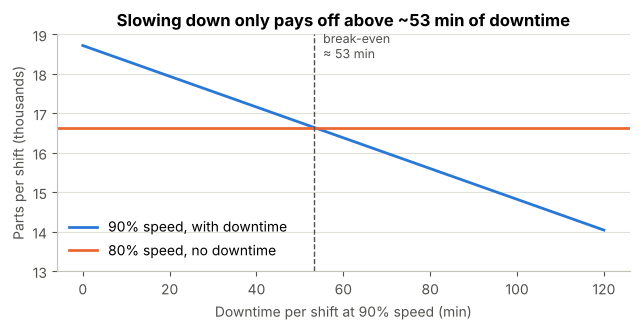

In [5]:
RATE_90 = 39
RATE_80 = RATE_90 * 80 / 90

def output(rate, minutes, downtime_min):
    return rate * (minutes - downtime_min)

# 6-minute observation period (72 s stop at 90%)
p90, p80 = output(RATE_90, 6, 72 / 60), output(RATE_80, 6, 0)
breakeven_6 = 6 - p80 / RATE_90
print(f"6-min period : 90% -> {p90:.0f} parts | 80% -> {p80:.0f} parts ({(p80 / p90 - 1) * 100:+.1f}%)")
print(f"               80% wins if the stop at 90% lasts more than {breakeven_6 * 60:.0f} s")

# Full shift (60 min downtime at 90%)
s90, s80 = output(RATE_90, SHIFT_MIN, 60), output(RATE_80, SHIFT_MIN, 0)
breakeven_shift = SHIFT_MIN - s80 / RATE_90
print(f"8-h shift    : 90% -> {s90:,.0f} parts | 80% -> {s80:,.0f} parts ({s80 - s90:+,.0f}; {(s80 / s90 - 1) * 100:+.2f}%)")
print(f"               80% wins if downtime at 90% exceeds {breakeven_shift:.1f} min per shift")

# Sensitivity chart
d = list(range(0, 121))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(d, [output(RATE_90, SHIFT_MIN, x) / 1000 for x in d], color=ACCENT, linewidth=2, label="90% speed, with downtime")
ax.axhline(s80 / 1000, color=SECOND, linewidth=2, label="80% speed, no downtime")
ax.axvline(breakeven_shift, color=INK, linestyle="--", linewidth=1)
ax.text(breakeven_shift + 2, 18.4, f"break-even\n≈ {breakeven_shift:.0f} min", color=INK, fontsize=9)
ax.set_xlabel("Downtime per shift at 90% speed (min)")
ax.set_ylabel("Parts per shift (thousands)")
ax.set_ylim(13, 19)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.legend(frameon=False, loc="lower left")
ax.set_title("Slowing down only pays off above ~53 min of downtime")
save(fig, "scenario2_edge_speed_breakeven.png")
plt.show()

**Reading the chart:** the gain at 60 min of downtime is small (+1.6%), and the decision depends entirely on the real downtime. The first step is therefore to **measure downtime over full shifts** before changing the speed.

## 4. Scenario 3: automated packaging and cart transfer

Today a worker applies the carton (17.4 s, measured) and lifts the unit onto a cart (4.6 s, assumed). An automated cell is assumed to need 15 s per unit.

$$\text{capacity} = \frac{\text{shift length (s)}}{\text{cycle time (s/unit)}}$$

In [6]:
current = 17.4 + 4.6
redesigned = 15.0
cap_now, cap_new = SHIFT_S / current, SHIFT_S / redesigned

print(f"Cycle time : {current:.1f} s -> {redesigned:.1f} s ({(redesigned / current - 1) * 100:.1f}%)")
print(f"Capacity   : {cap_now:,.0f} -> {cap_new:,.0f} units per shift "
      f"(+{cap_new - cap_now:,.0f}; {(cap_new / cap_now - 1) * 100:+.1f}%)")
print("Note: theoretical station capacity, excluding breaks, downtime and other line constraints.")

Cycle time : 22.0 s -> 15.0 s (-31.8%)
Capacity   : 1,309 -> 1,920 units per shift (+611; +46.7%)
Note: theoretical station capacity, excluding breaks, downtime and other line constraints.


## 5. Scenario 4: Autonomous Mobile Robots (AMRs) for internal transport

Carts with fronts and WIP parts are pushed by hand, and parked carts block aisles.

- Cabinets per shift ≈ 2.8 cabinets/min × 480 min = 1,344, at ~11 per cart ≈ **120 trips**
- Today: 5 min of worker time per trip (push + walk back). With AMRs: 1 min (hook up the cart).

In [7]:
cabinets = 2.8 * SHIFT_MIN
trips = round(cabinets / 11, -1)          # ≈ 120 trips, rounded as in the report
worker_now, worker_amr = trips * 5 / 60, trips * 1 / 60
blocked_now, blocked_amr = 20 * 2, 5

print(f"Cabinets per shift: {cabinets:,.0f}  ->  ~{trips:.0f} cart trips")
print(f"Worker time  : {worker_now:.0f} h -> {worker_amr:.0f} h per shift "
      f"({(worker_amr / worker_now - 1) * 100:.0f}%; {worker_now - worker_amr:.0f} h released)")
print(f"Blocked aisle: {blocked_now} min -> {blocked_amr} min per shift ({(blocked_amr / blocked_now - 1) * 100:.0f}%)")

Cabinets per shift: 1,344  ->  ~120 cart trips
Worker time  : 10 h -> 2 h per shift (-80%; 8 h released)
Blocked aisle: 40 min -> 5 min per shift (-88%)


## 6. Summary of the scenarios

                           Scenario                     Metric  Current  Scenario value        Type Change
           Pick-by-Light (2 s/item)           Orders per shift      192             232 Incremental  20.8%
        Edge finishing at 80% speed            Parts per shift    16380           16640 Incremental   1.6%
Automated packaging & cart transfer Units per shift (capacity)     1309            1920     Radical  46.7%
        AMRs for internal transport     Worker hours per shift       10               2     Radical -80.0%


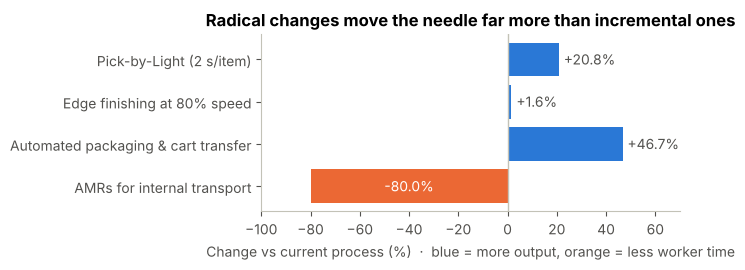

In [8]:
summary = pd.DataFrame([
    ["Pick-by-Light (2 s/item)", "Orders per shift", 192, round(orders_per_shift(2)), "Incremental"],
    ["Edge finishing at 80% speed", "Parts per shift", round(s90), round(s80), "Incremental"],
    ["Automated packaging & cart transfer", "Units per shift (capacity)", round(cap_now), round(cap_new), "Radical"],
    ["AMRs for internal transport", "Worker hours per shift", round(worker_now), round(worker_amr), "Radical"],
], columns=["Scenario", "Metric", "Current", "Scenario value", "Type"])
summary["Change"] = ((summary["Scenario value"] / summary["Current"] - 1) * 100).round(1).astype(str) + "%"
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 2.8))
chg = (summary["Scenario value"] / summary["Current"] - 1) * 100
labels = summary["Scenario"]
colors = [ACCENT if c > 0 else SECOND for c in chg]
bars = ax.barh(labels, chg, color=colors)
for b, c in zip(bars, chg):
    if c > 0:
        ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2, f"{c:+.1f}%", va="center", color=INK)
    else:
        ax.text(b.get_width() / 2, b.get_y() + b.get_height() / 2, f"{c:+.1f}%", ha="center", va="center", color="white")
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.invert_yaxis()
ax.set_xlim(-100, 70)
ax.set_xlabel("Change vs current process (%)  ·  blue = more output, orange = less worker time")
ax.set_title("Radical changes move the needle far more than incremental ones")
save(fig, "scenario_summary.png")
plt.show()

## Conclusions

- **Measurements:** short tour observations already reveal disruptions (−44% output in one minute of edge finishing).
- **Incremental improvements** give modest gains (+21% picking orders, +1.6% edge-finishing output) and depend strongly on assumptions; the break-even analysis shows *what* to measure first.
- **Radical improvements** (automated packaging, AMRs) offer much larger effects, but need investment and a pilot.

## Limitations

- Observations are short snapshots from a VR tour (minutes, not full shifts).
- Many parameters are assumptions, listed in `scenario_assumptions.csv`.
- Capacities are theoretical station capacities: breaks, downtime and line balancing are not modelled.